# 06 · Sleeve 3: equity versus freight

Each stock is regressed on its segment freight index and the market over a trailing year; when its recent return departs from what that relationship implies, the sleeve trades it back, segment-neutral.

In [1]:
import json, warnings
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from shiplab import charts
from shiplab.config import DATA
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3, "display.width", 140)
R = DATA / "results"
perf = pd.read_csv(R / "performance_by_period.csv")
strat = pd.read_parquet(R / "strategy_returns.parquet")
bench = pd.read_parquet(R / "benchmark_returns.parquet")
dsr = json.load(open(R / "deflated_sharpe.json"))
def row(period, series="Strategy"):
    return perf[(perf.period == period) & (perf.series == series)].iloc[0]

In [2]:
from shiplab import metrics
grid = pd.read_parquet(R / "grid_returns.parquet")
picks = pd.read_csv(R / "walk_forward_picks.csv", index_col=0)
cols = [c for c in grid.columns if c.startswith("residual")]
tab = pd.DataFrame({c: metrics.summary(grid[c].loc["2011":"2022"]) for c in cols}).T
display(tab[["ann_return", "ann_vol", "sharpe", "max_drawdown"]].round(3))
display(picks[["residual"]].rename(columns={"residual": "chosen for the year (prior data only)"}))

,ann_return,ann_vol,sharpe,max_drawdown
residual|entry=0.75|h=10,0.007,0.026,0.272,-0.073
residual|entry=0.75|h=20,0.009,0.026,0.369,-0.069
residual|entry=1.0|h=10,-0.003,0.022,-0.136,-0.087
residual|entry=1.0|h=20,0.007,0.019,0.358,-0.038
residual|entry=1.5|h=10,-0.003,0.013,-0.196,-0.068
residual|entry=1.5|h=20,-0.002,0.013,-0.141,-0.038


,chosen for the year (prior data only)
2014,NaN
2015,NaN
2016,residual|entry=0.75|h=20
2017,residual|entry=0.75|h=20
2018,residual|entry=0.75|h=20
2019,residual|entry=0.75|h=20
2020,residual|entry=0.75|h=20
2021,residual|entry=0.75|h=20
2022,residual|entry=0.75|h=10


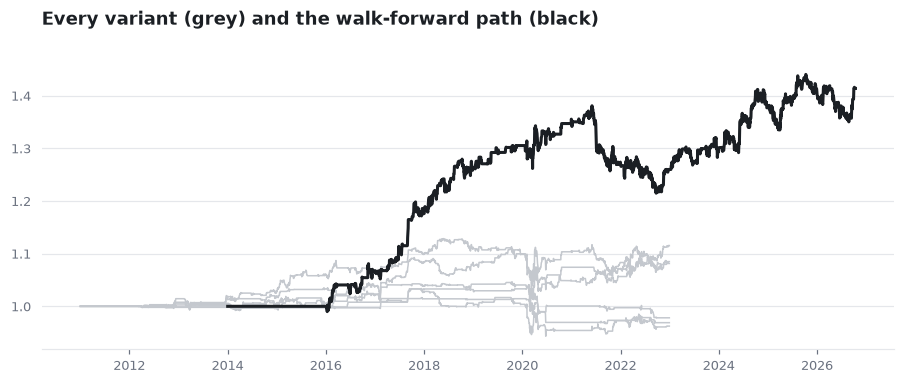

In [3]:
from shiplab import style
style.apply()
fig, ax = plt.subplots(figsize=(10, 3.4))
for c in cols:
    ax.plot((1 + grid[c].loc["2011":"2022"]).cumprod(), color="#C4C8CE", lw=1)
if "sleeve_residual" in strat:
    s = strat["sleeve_residual"].dropna()
    ax.plot((1 + s).cumprod(), color=style.INK, lw=2)
ax.set_title("Every variant (grey) and the walk-forward path (black)")
plt.show()